## Objetivo y fundamento teórico

Un árbol **CART** de clasificación divide recursivamente el espacio de variables eligiendo, en cada nodo,
la característica $f$ y el punto de corte $sp$ que maximizan la **ganancia de información**:

$$IG(\text{nodo}) = I(\text{nodo}) - \left(\frac{N_{izq}}{N} I(\text{nodo}_{izq}) + \frac{N_{der}}{N} I(\text{nodo}_{der})\right)$$

donde la impureza $I$ puede medirse con:

| Criterio | Fórmula | Interpretación |
|---|---|---|
| **Índice Gini** | $I_G = 1 - \sum_{i=1}^{C} p_i^2$ | Probabilidad de clasificar mal un elemento al azar (cálculo más rápido). |
| **Entropía** | $H = -\sum_{i=1}^{C} p_i \log_2 p_i$ | Desorden / incertidumbre de la información. |

La **Regresión Logística** es un modelo lineal que estima $P(y=1\mid x) = \sigma(w^\top x + b)$; requiere
estandarizar las variables (se ajusta el `StandardScaler` **solo** con datos de entrenamiento dentro de un `Pipeline`).

**Plan:** (1) exploración de datos, (2) partición estratificada 80/20, (3) entrenamiento de árboles Gini y Entropía
(sin podar y podados) y Regresión Logística, (4) validación cruzada estratificada 10-Fold, (5) métricas en prueba,
matrices de confusión, curvas ROC, curvas de complejidad e importancia de variables, (6) prueba estadística y conclusión.

In [1]:
# Librerías y configuración global de reproducibilidad
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
REPO_RAW = "https://raw.githubusercontent.com/Edwardmamani/ML-UNAP-Tarea-Ejecucion-03/main"


def load_csv(name):
    """Carga un CSV desde data/ (local) o desde el repositorio GitHub (Colab)."""
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else f"{REPO_RAW}/data/{name}")


def savefig(name):
    """Guarda la figura actual en figures/ (se reutiliza en el informe .docx)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")


def bootstrap_ci(y_true, y_score, metric, n_boot=1000, seed=RANDOM_STATE):
    """Intervalo de confianza bootstrap al 95% de una métrica sobre el conjunto de prueba."""
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2 and metric.__name__ == "roc_auc_score":
            continue
        vals.append(metric(y_true[idx], y_score[idx]))
    return np.percentile(vals, [2.5, 97.5])


def save_results(obj, name):
    """Guarda los resultados en results/<name>.json (insumo del informe)."""
    with open(f"results/{name}.json", "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False,
                  default=lambda o: o.item() if hasattr(o, "item") else str(o))


def plot_roc(ax, model, X_eval, y_eval, name, color=None, lw=1.8):
    """Dibuja la curva ROC de un modelo (compatible con cualquier versión de scikit-learn)."""
    from sklearn.metrics import roc_curve, roc_auc_score
    score = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_eval, score)
    ax.plot(fpr, tpr, color=color, lw=lw, label=f"{name} (AUC = {roc_auc_score(y_eval, score):.3f})")
    ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
    ax.legend(loc="lower right", fontsize=8)


print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.4.6


## 1. Carga y exploración del dataset

In [2]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # 0 = maligno, 1 = benigno
df = data.frame

print("Dimensiones de X:", X.shape)
print("Valores nulos totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("\nDistribución de clases:")
print(y.value_counts().rename(index={0: "maligno (0)", 1: "benigno (1)"}))
df.describe().T[["mean", "std", "min", "max"]].head(10).round(3)

Dimensiones de X: (569, 30)
Valores nulos totales: 0
Filas duplicadas: 0

Distribución de clases:
target
benigno (1)    357
maligno (0)    212
Name: count, dtype: int64


,mean,std,min,max
mean radius,14.127,3.524,6.981,28.110
mean texture,19.290,4.301,9.710,39.280
mean perimeter,91.969,24.299,43.790,188.500
mean area,654.889,351.914,143.500,2501.000
mean smoothness,0.096,0.014,0.053,0.163
mean compactness,0.104,0.053,0.019,0.345
mean concavity,0.089,0.080,0.000,0.427
mean concave points,0.049,0.039,0.000,0.201
mean symmetry,0.181,0.027,0.106,0.304
mean fractal dimension,0.063,0.007,0.050,0.097


_(análisis pendiente)_

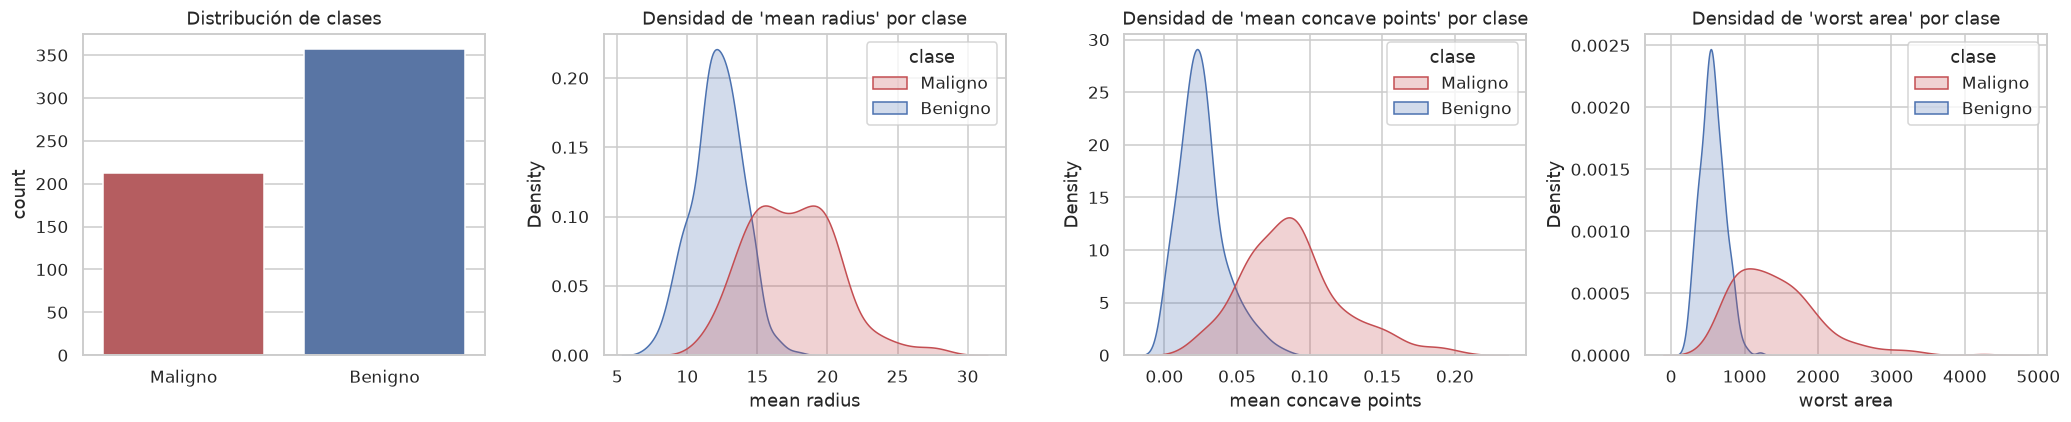

In [3]:
labels = y.map({0: "Maligno", 1: "Benigno"})
pal = {"Maligno": "#C44E52", "Benigno": "#4C72B0"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
sns.countplot(x=labels, hue=labels, palette=pal, legend=False, ax=axes[0])
axes[0].set_title("Distribución de clases"); axes[0].set_xlabel("")
for ax, feat in zip(axes[1:], ["mean radius", "mean concave points", "worst area"]):
    sns.kdeplot(data=df.assign(clase=labels), x=feat, hue="clase", fill=True,
                common_norm=False, palette=pal, ax=ax)
    ax.set_title(f"Densidad de '{feat}' por clase")
plt.tight_layout(); savefig("item1_eda"); plt.show()

_(análisis pendiente)_

## 2. Partición estratificada entrenamiento / prueba (80/20)

In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de benignos  train = %.3f | test = %.3f" % (y_train.mean(), y_test.mean()))

Train: (455, 30) | Test: (114, 30)
Proporción de benignos  train = 0.626 | test = 0.632


La estratificación conserva la proporción de clases (≈63 % benignos) en ambos subconjuntos. El conjunto de
prueba **no se utiliza** para ajustar ningún hiperparámetro: solo se usa para la evaluación final.

## 3. Definición de modelos

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "CART Gini (sin podar)": DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE),
    "CART Entropía (sin podar)": DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE),
    "CART Gini (podado)": DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_leaf=5,
                                                 random_state=RANDOM_STATE),
    "CART Entropía (podado)": DecisionTreeClassifier(criterion="entropy", max_depth=4, min_samples_leaf=5,
                                                     random_state=RANDOM_STATE),
    "Regresión Logística": make_pipeline(StandardScaler(),
                                         LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
}
for k, v in models.items():
    print(f"{k:28s} -> {v}")

CART Gini (sin podar)        -> DecisionTreeClassifier(random_state=42)
CART Entropía (sin podar)    -> DecisionTreeClassifier(criterion='entropy', random_state=42)
CART Gini (podado)           -> DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
CART Entropía (podado)       -> DecisionTreeClassifier(criterion='entropy', max_depth=4, min_samples_leaf=5,
                       random_state=42)
Regresión Logística          -> Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=5000, random_state=42))])


Se entrenan **cinco** modelos: dos árboles completamente desarrollados (para observar la alta varianza de CART),
dos árboles **podados** (`max_depth=4`, `min_samples_leaf=5`) para controlar el sobreajuste, y la Regresión
Logística estandarizada como modelo lineal de referencia.

## 4. Entrenamiento, validación cruzada 10-Fold y evaluación en prueba

In [6]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, make_scorer, confusion_matrix)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "roc_auc": "roc_auc",
           "f1_maligno": make_scorer(f1_score, pos_label=0)}

rows, cv_acc = [], {}
for name, model in models.items():
    cvres = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    t0 = time.perf_counter(); model.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    y_pred = model.predict(X_test); y_proba = model.predict_proba(X_test)[:, 1]
    # filas = real, columnas = predicho; orden de etiquetas [maligno(0), benigno(1)]
    mal_ok, mal_como_ben, ben_como_mal, ben_ok = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    cv_acc[name] = cvres["test_accuracy"]
    est = model if hasattr(model, "get_depth") else None
    rows.append({
        "Modelo": name,
        "Acc. train": accuracy_score(y_train, model.predict(X_train)),
        "Acc. CV (media)": cvres["test_accuracy"].mean(),
        "Acc. CV (std)": cvres["test_accuracy"].std(),
        "ROC-AUC CV": cvres["test_roc_auc"].mean(),
        "Acc. test": accuracy_score(y_test, y_pred),
        "Precisión maligno": precision_score(y_test, y_pred, pos_label=0),
        "Recall maligno": recall_score(y_test, y_pred, pos_label=0),
        "F1 maligno": f1_score(y_test, y_pred, pos_label=0),
        "ROC-AUC test": roc_auc_score(y_test, y_proba),
        "Malignos no detectados (FN)": int(mal_como_ben),
        "Profundidad": est.get_depth() if est else np.nan,
        "Hojas": est.get_n_leaves() if est else np.nan,
        "Tiempo fit (s)": fit_t,
    })
results = pd.DataFrame(rows).set_index("Modelo")
results.round(4)

,Acc. train,Acc. CV (media),Acc. CV (std),ROC-AUC CV,Acc. test,Precisión maligno,Recall maligno,F1 maligno,ROC-AUC test,Malignos no detectados (FN),Profundidad,Hojas,Tiempo fit (s)
Modelo,,,,,,,,,,,,,
CART Gini (sin podar),1.0000,0.9253,0.0416,0.9214,0.9123,0.8478,0.9286,0.8864,0.9157,3,7.0,19.0,0.0105
CART Entropía (sin podar),1.0000,0.9230,0.0406,0.9183,0.9123,0.8333,0.9524,0.8889,0.9206,2,6.0,16.0,0.0122
CART Gini (podado),0.9758,0.9362,0.0386,0.9589,0.9211,0.8837,0.9048,0.8941,0.9263,4,4.0,10.0,0.0058
CART Entropía (podado),0.9736,0.9319,0.0409,0.9486,0.8772,0.7800,0.9286,0.8478,0.9593,3,4.0,10.0,0.0068
Regresión Logística,0.9890,0.9824,0.0133,0.9945,0.9825,0.9762,0.9762,0.9762,0.9954,1,NaN,NaN,0.0653


_(análisis pendiente)_

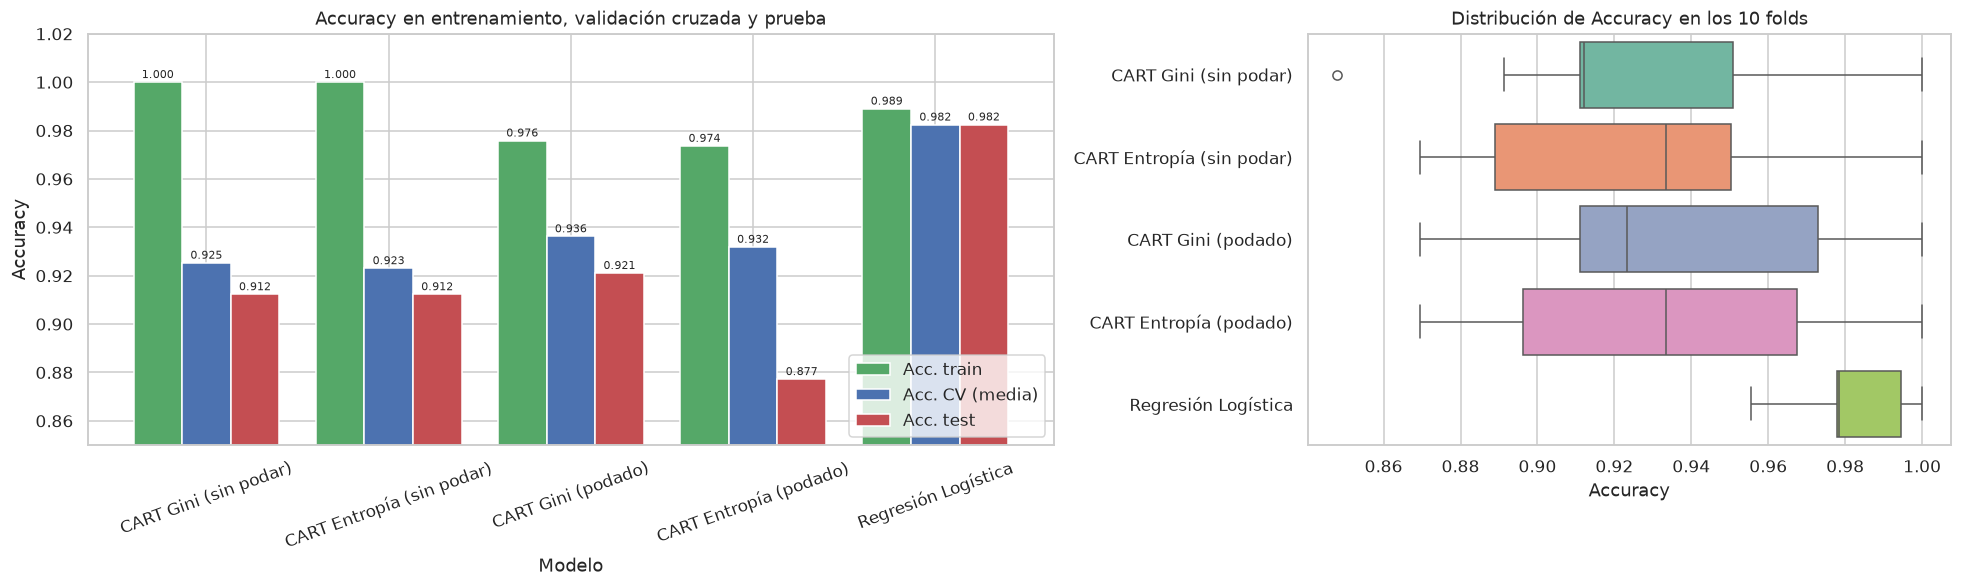

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
plot_df = results[["Acc. train", "Acc. CV (media)", "Acc. test"]]
plot_df.plot(kind="bar", ax=axes[0], color=["#55A868", "#4C72B0", "#C44E52"], width=0.8)
axes[0].set_ylim(0.85, 1.02); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Accuracy en entrenamiento, validación cruzada y prueba")
axes[0].tick_params(axis="x", rotation=20)
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=7, padding=1)
axes[0].legend(loc="lower right")
cv_df = pd.DataFrame(cv_acc).melt(var_name="Modelo", value_name="Accuracy")
sns.boxplot(data=cv_df, y="Modelo", x="Accuracy", hue="Modelo", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Distribución de Accuracy en los 10 folds"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("item1_comparacion"); plt.show()

_(análisis pendiente)_

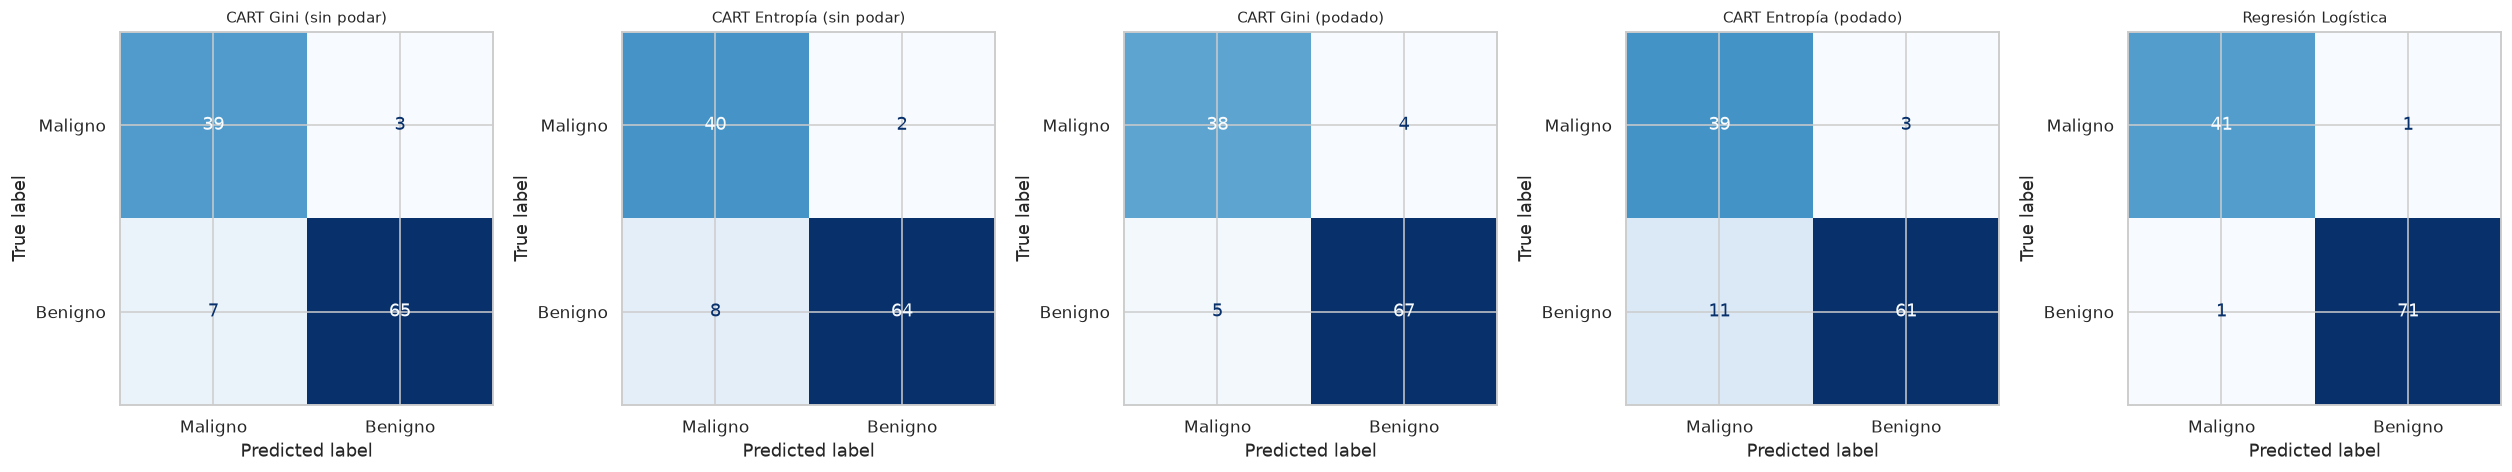

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 5, figsize=(23, 4.3))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), labels=[0, 1],
                                            display_labels=["Maligno", "Benigno"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); savefig("item1_confusion"); plt.show()

_(análisis pendiente)_

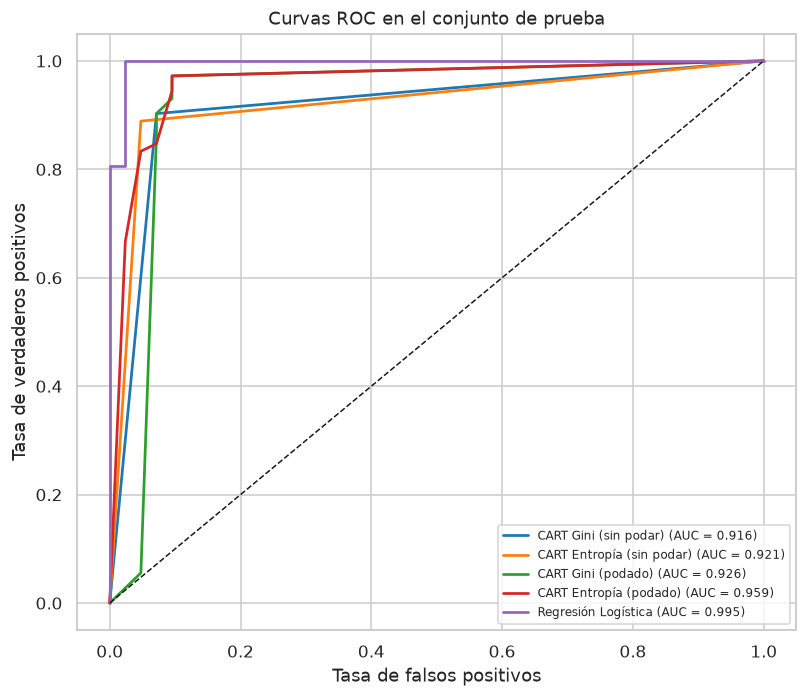

In [9]:
# curvas ROC con el helper plot_roc (definido en la celda de configuración)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
for (name, model), col in zip(models.items(), sns.color_palette("tab10")):
    plot_roc(ax, model, X_test, y_test, name, color=col)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("Curvas ROC en el conjunto de prueba")
plt.tight_layout(); savefig("item1_roc"); plt.show()

_(análisis pendiente)_

## 5. Curva de complejidad: Gini vs. Entropía según `max_depth`

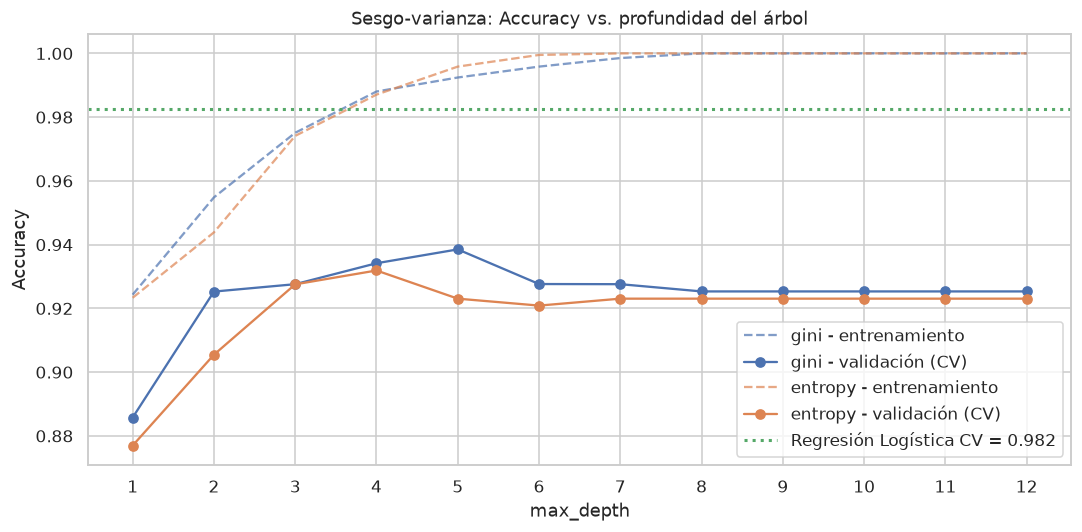

Mejor max_depth por CV: {'gini': 5, 'entropy': 4} | Acc CV máx: {'gini': np.float64(0.9385), 'entropy': np.float64(0.9319)}


In [10]:
depths = list(range(1, 13))
curves = {}
for crit in ["gini", "entropy"]:
    tr, va = [], []
    for d in depths:
        m = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=RANDOM_STATE)
        s = cross_validate(m, X_train, y_train, cv=cv, scoring="accuracy",
                           return_train_score=True, n_jobs=-1)
        tr.append(s["train_score"].mean()); va.append(s["test_score"].mean())
    curves[crit] = (tr, va)

lr_cv = results.loc["Regresión Logística", "Acc. CV (media)"]
fig, ax = plt.subplots(figsize=(10, 5))
for crit, col in [("gini", "#4C72B0"), ("entropy", "#DD8452")]:
    ax.plot(depths, curves[crit][0], "--", color=col, alpha=0.7, label=f"{crit} - entrenamiento")
    ax.plot(depths, curves[crit][1], "-o", color=col, label=f"{crit} - validación (CV)")
ax.axhline(lr_cv, color="#55A868", ls=":", lw=2, label=f"Regresión Logística CV = {lr_cv:.3f}")
ax.set_xlabel("max_depth"); ax.set_ylabel("Accuracy"); ax.set_xticks(depths)
ax.set_title("Sesgo-varianza: Accuracy vs. profundidad del árbol")
ax.legend(); plt.tight_layout(); savefig("item1_complejidad"); plt.show()

best_depth = {c: depths[int(np.argmax(curves[c][1]))] for c in curves}
print("Mejor max_depth por CV:", best_depth,
      "| Acc CV máx:", {c: round(max(curves[c][1]), 4) for c in curves})

_(análisis pendiente)_

## 6. Interpretabilidad: estructura del árbol e importancia de variables

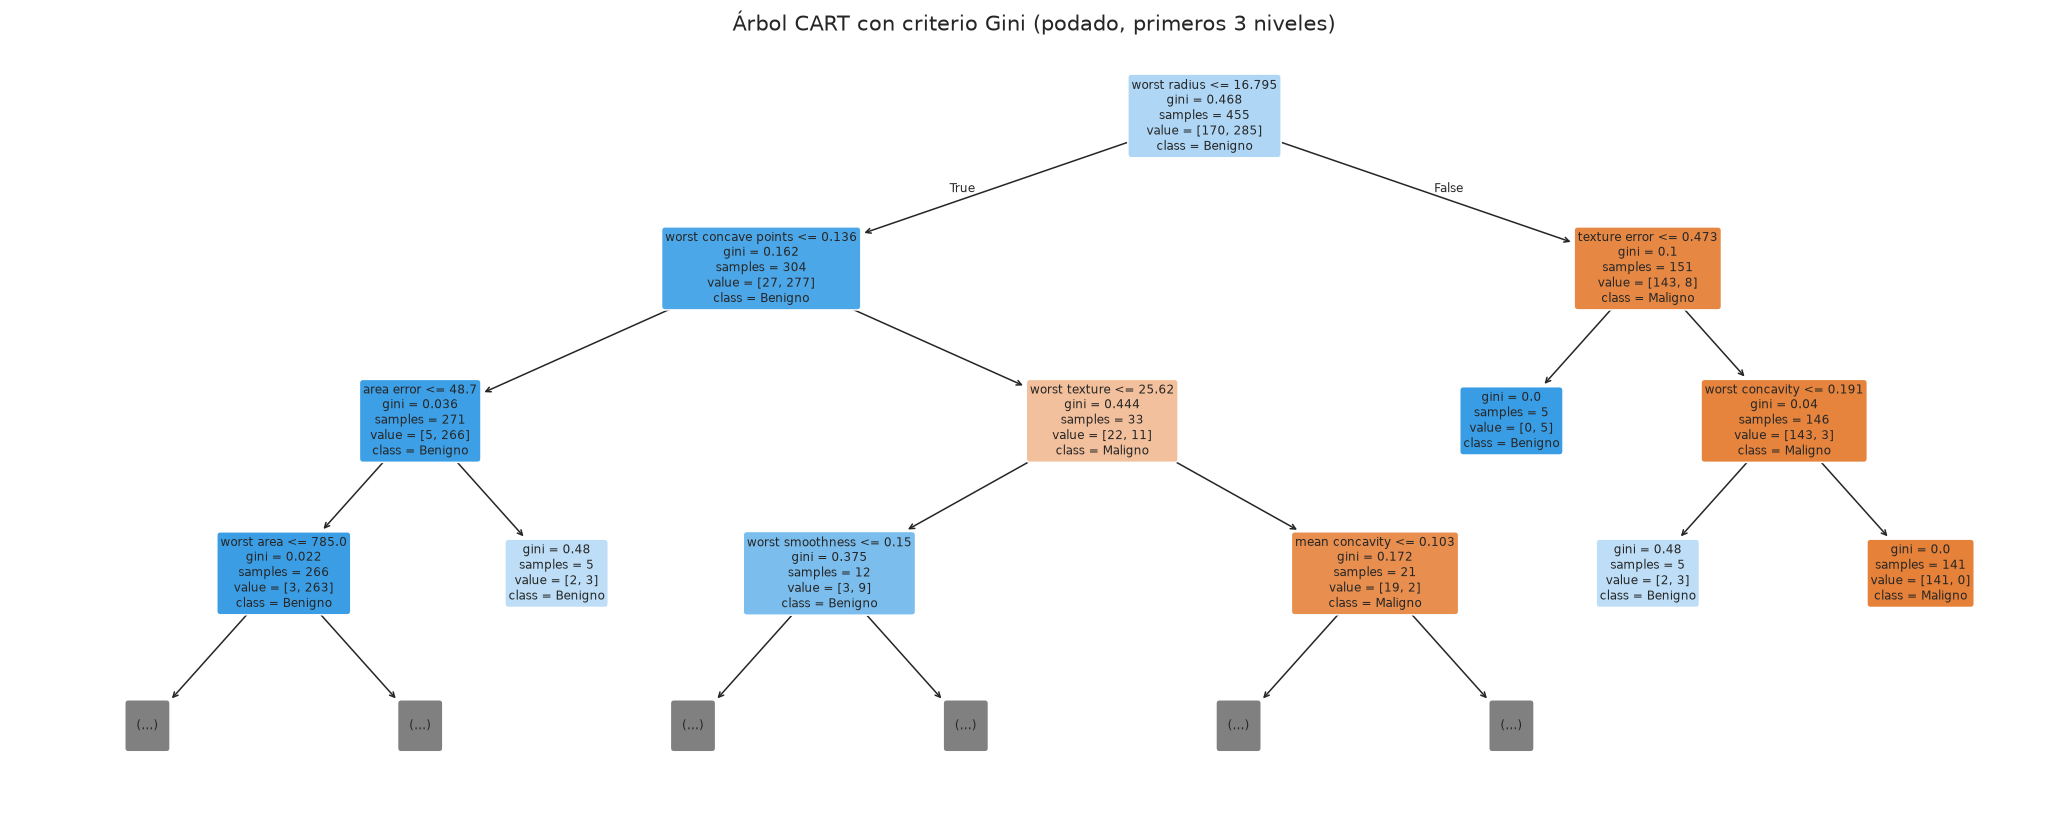

In [11]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(24, 9))
plot_tree(models["CART Gini (podado)"], feature_names=list(X.columns), class_names=["Maligno", "Benigno"],
          filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax, impurity=True, proportion=False)
ax.set_title("Árbol CART con criterio Gini (podado, primeros 3 niveles)", fontsize=14)
savefig("item1_arbol"); plt.show()

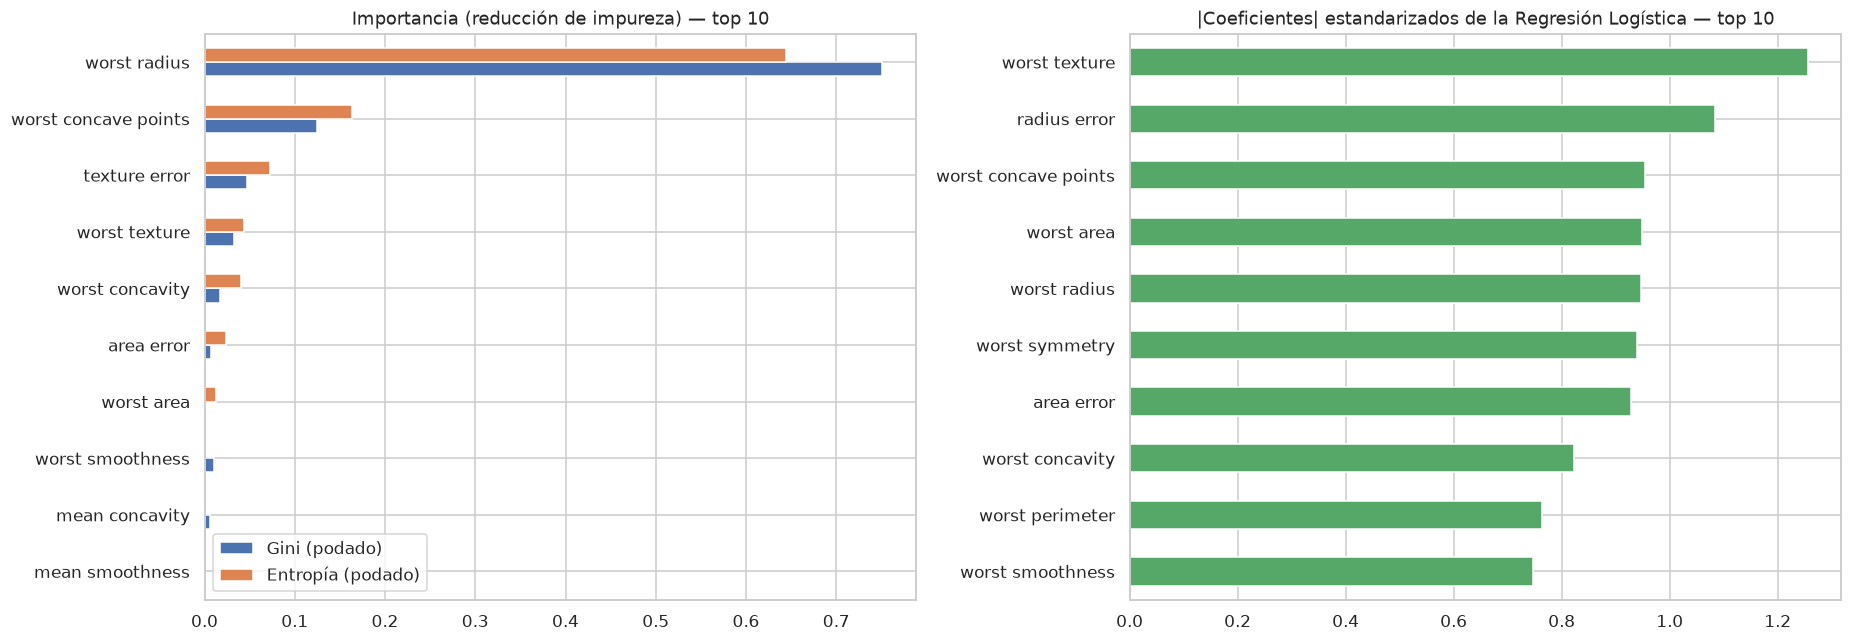

Variables con importancia > 0  Gini: 9 | Entropía: 7


In [12]:
imp = pd.DataFrame({
    "Gini (podado)": models["CART Gini (podado)"].feature_importances_,
    "Entropía (podado)": models["CART Entropía (podado)"].feature_importances_,
}, index=X.columns)
coef = pd.Series(np.abs(models["Regresión Logística"][-1].coef_[0]), index=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
top = imp.max(axis=1).sort_values(ascending=False).head(10).index
imp.loc[top].iloc[::-1].plot(kind="barh", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Importancia (reducción de impureza) — top 10")
coef.sort_values().tail(10).plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("|Coeficientes| estandarizados de la Regresión Logística — top 10")
plt.tight_layout(); savefig("item1_importancia"); plt.show()
print("Variables con importancia > 0  Gini:", int((imp['Gini (podado)'] > 0).sum()),
      "| Entropía:", int((imp['Entropía (podado)'] > 0).sum()))

_(análisis pendiente)_

## 7. Significancia estadística (CV repetida 10×3 + prueba de Wilcoxon) e IC bootstrap

In [13]:
from scipy.stats import wilcoxon
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
names = ["CART Gini (podado)", "CART Entropía (podado)", "CART Gini (sin podar)", "Regresión Logística"]
rep = {n: cross_val_score(models[n], X_train, y_train, cv=rcv, scoring="accuracy", n_jobs=-1) for n in names}
pairs = [("Regresión Logística", "CART Gini (podado)"), ("Regresión Logística", "CART Entropía (podado)"),
         ("CART Gini (podado)", "CART Entropía (podado)"), ("CART Gini (podado)", "CART Gini (sin podar)")]
stats_rows = []
for a, b in pairs:
    p = wilcoxon(rep[a], rep[b], zero_method="zsplit").pvalue
    stats_rows.append({"Comparación (A vs B)": f"{a} vs {b}", "Acc. media A": rep[a].mean(),
                       "Acc. media B": rep[b].mean(), "Diferencia A-B": (rep[a] - rep[b]).mean(),
                       "p-valor Wilcoxon": p, "Significativo (α=0.05)": "Sí" if p < 0.05 else "No"})
stats_df = pd.DataFrame(stats_rows)

ci = {n: bootstrap_ci(y_test, models[n].predict(X_test), accuracy_score) for n in models}
ci_df = pd.DataFrame(ci, index=["IC95% inf", "IC95% sup"]).T
display(stats_df.round(4)); display(ci_df.round(4))

,Comparación (A vs B),Acc. media A,Acc. media B,Diferencia A-B,p-valor Wilcoxon,Significativo (α=0.05)
0,Regresión Logística vs CART Gini (podado),0.9780,0.9312,0.0468,0.0000,Sí
1,Regresión Logística vs CART Entropía (podado),0.9780,0.9327,0.0453,0.0001,Sí
2,CART Gini (podado) vs CART Entropía (podado),0.9312,0.9327,-0.0014,0.6549,No
3,CART Gini (podado) vs CART Gini (sin podar),0.9312,0.9188,0.0124,0.0150,Sí


,IC95% inf,IC95% sup
CART Gini (sin podar),0.8596,0.9561
CART Entropía (sin podar),0.8596,0.9649
CART Gini (podado),0.8684,0.9649
CART Entropía (podado),0.8070,0.9386
Regresión Logística,0.9561,1.0000


_(análisis pendiente)_

In [14]:
save_results({
    "results": results.reset_index().to_dict(orient="records"),
    "stats": stats_df.to_dict(orient="records"),
    "ci": ci_df.reset_index().rename(columns={"index": "Modelo"}).to_dict(orient="records"),
    "best_depth": best_depth,
    "curves": {c: {"train": curves[c][0], "cv": curves[c][1]} for c in curves},
}, "item1")
print("Resultados guardados en results/item1.json")

Resultados guardados en results/item1.json


## Conclusiones
_(pendiente)_